# Notebook 0 - Configurazione / Soluzione

Questo notebook è un notebook di base per verificare il tuo livello iniziale e per presentarti come si svolgerà il corso.

## Configurare tutto

Ora, seguiamo passo passo, molto rapidamente, questo [file qui](../../resources/setup.md).\
Una volta fatto tutto ciò che è descritto lì, possiamo procedere con il nostro esercizio di riscaldamento!

## Basi di Python

Presumo che abbiate già un po' di esperienza con Python, ma sapete, è molto più facile verificarlo di persona invece di darlo per scontato.\
Quindi, iniziamo con un esercizio di riscaldamento.\
Vi darò alcuni frammenti di codice e dovrete completare il codice rimanente (le righe `TODO`).

### Congettura di Collatz

Non so quanti di voi abbiano mai sentito parlare di questa congettura: è una congettura non dimostrata che afferma qualcosa del genere:

Prendi un numero intero qualsiasi $n \in \mathbb{N}$

* ora, se il numero è pari, dividilo per $2$, $n \to \frac{n}{2}$
* altrimenti, moltiplicalo per $3$ e aggiungi $1$, $n \to 3n + 1$
* ripeti

alla fine, indipendentemente dal numero di partenza, si finirà nella sequenza infinita $4, 2, 1, 4, 2, 1, ...$.

Ora, penso proprio che possiate iniziare implementando una funzione semplice, che ne dite?

In [3]:
def collatz_step(n):

    # Controllo se n è pari. Se lo è, restituisco la metà di n
    if n%2 == 0: 
        return int(n/2)
    
    # Altrimenti n è dispari, quindi restiisco 3n + 1
    return 3*n + 1

    # NB: Sto implementando un singolo passo, non l'intera procedura

Una volta che abbiamo la funzione per il singolo passo, facciamo qualcosa di *elegante* (non proprio, comunque).\
Calcoliamo quanti passi impiega un dato numero per arrivare al ciclo $4, 2, 1, ...$.\
Per definizione $4, 2, 1$ sono già nel ciclo, quindi il numero di passi per ciascuno di essi è semplicemente $0$.

In [4]:
def steps_to_loop(n):

    # Inizializzo il contatore dei passi a 0
    c = 0

    # Continuo a fare un passo di Collatz finché n non entra nel ciclo 4, 2, 1
    while (n != 4 and n != 2 and n != 1):
        n = collatz_step(n)
        c = c + 1
        
    # Restituisco il numero di passi effettuati
    return c

Ok, ci siamo? Bene. Rendiamo le cose un po' più difficili. Proviamo a raccogliere, per un dato intervallo di numeri, il numero di passi che ciascun numero dell'intervallo impiega per entrare nel ciclo.\
Usiamo un dizionario per memorizzare l'intervallo di numeri, ok?

In [5]:
# Definisco gli estremi dell'intervallo di numeri da analizzare
n_min = 1
n_max = 1000000

In [6]:
# Costruisco un dizionario {numero : passi_per_il_ciclo} per tutto l'intervallo
n_steps_to_loop = {i : steps_to_loop(i) for i in range (n_min, n_max)}

Ok, cosa pensate che siano le prestazioni?\
Voglio dire, per questo benchmark possiamo semplicemente guardare il tempo che la cella ha impiegato per essere eseguita.\
Ma possiamo anche provare qualcosa di un po' più *sofisticato*: usiamo la funzione `perf_counter()` dal modulo `time`.

In [7]:
from time import perf_counter

In [8]:
# Registro il tempo di inizio
t0 = perf_counter()

# Eseguo la versione non ottimizzata su tutto l'intervallo
n_steps_to_loop = {i : steps_to_loop(i) for i in range (n_min, n_max)}

# Registro il tempo di fine e calcolo la differenza
t1 = perf_counter()
delta_t = t1 - t0

# Stampo il tempo impiegato
print(f"Tempo richiesto per la versione non ottimizzata : {delta_t}")

Tempo richiesto per la versione non ottimizzata : 19.090838799000267


Ok, pensate che sia un buon modo per calcolare la procedura? Vedete qualche possibile miglioramento?\
Proviamo qualcosa di un po' più difficile, sfruttando il fatto che mentre calcoliamo la serie di Collatz di un numero, useremo molte serie di Collatz già esistenti di altri numeri.\
Questo è qualcosa che possiamo fare abbastanza facilmente con i dizionari!

Se non avete capito, seguite questo esempio:

sapete che $3$ ha `steps_to_loop` uguale a $5$.\
Consideriamo ora il numero $6$:\
6 non è nel ciclo $4, 2, 1, ...$, quindi avrà bisogno di almeno 1 passo per entrare nel ciclo.\
Se lo dividete per 2 (seguendo `collatz_step`) diventerà un 3.\
Ora conoscete già il valore per 3!\
Quindi non ricalcolate tutto, usate semplicemente ciò che già sapete per ottenere che $6$ ha `steps_to_loop` uguale a $6$ (che è semplicemente $5+1$)!

In [9]:
# Inizializzo il dizionario con i valori noti del ciclo 4, 2, 1
n_steps_to_loop = {}
n_steps_to_loop[1] = 0
n_steps_to_loop[2] = 0
n_steps_to_loop[4] = 0

# Definisco la funzione ricorsiva che sfrutta i valori già calcolati
def recursive_steps_to_loop(n):
    # Se n non è ancora nel dizionario, lo calcolo ricorsivamente
    if n not in n_steps_to_loop:
        n_steps_to_loop[n] = 1 + recursive_steps_to_loop(collatz_step(n))
    # Restituisco il valore memorizzato
    return n_steps_to_loop[n]

# Misuro il tempo di esecuzione della versione ottimizzata
t0 = perf_counter()

for i in range (n_min, n_max):
    recursive_steps_to_loop(i)

t1 = perf_counter()
delta_t = t1 - t0
print(f"Tempo richiesto per la versione ottimizzata : {delta_t}")

Tempo richiesto per la versione ottimizzata : 1.0287477810006749


Rimuoviamo anche tutte le chiavi aggiuntive aggiunte al dizionario che non appartengono all'intervallo desiderato.

In [10]:
# Recupero tutte le chiavi del dizionario
keys = list(n_steps_to_loop.keys())

# Elimino le chiavi che superano n_max, per tenere solo l'intervallo desiderato
for n in keys:
    if n > n_max:
        del n_steps_to_loop[n]

Ottimo! Sembra che abbia funzionato, vero?\
Una semplice implementazione ricorsiva (avreste potuto usare anche altre tecniche) dovrebbe portare il tempo di calcolo (nell'intervallo $[1, 10^6]$) da $\approx 9$ a $\approx 0.5$ secondi.\
**È un miglioramento di $\times 18$! Ottimo!**

Se non ha funzionato, non preoccupatevi. Volevo testare la vostra conoscenza dei dizionari e degli algoritmi! Anche se potrebbe sembrare non correlato, troverete utile a un certo punto questa tecnica di ottimizzazione usata qui, chiamata **memoizzazione**.

Ovviamente dovreste sapere che Python non è il linguaggio di programmazione giusto per fare ottimizzazione, ma comunque è bene avere un'idea di come l'ottimizzazione possa ridurre davvero molto il calcolo!

Ora concludiamo questo semplice esercizio di riscaldamento con un po' di visualizzazione.\
Perché un data scientist deve sempre sapere come far visualizzare i propri risultati agli altri!

In [11]:
from matplotlib import pyplot as plt

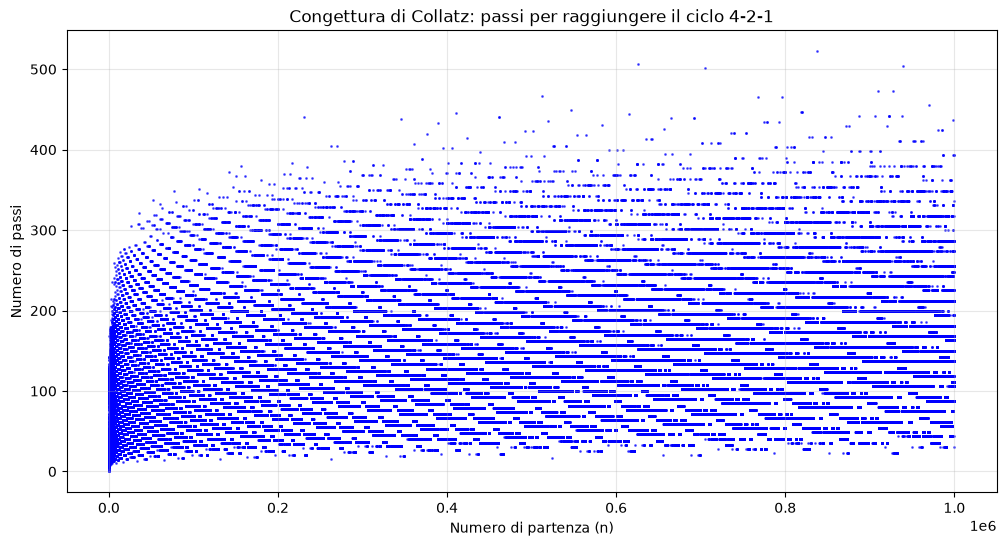

In [12]:
# Estraggo i dati dal dizionario popolato in precedenza
x = list(n_steps_to_loop.keys())   # numeri di partenza
y = list(n_steps_to_loop.values()) # numero di passi per ciascun numero

# Creo il grafico a dispersione
plt.figure(figsize=(12, 6))
plt.scatter(x, y, s=1, alpha=0.6, color='blue') # s=1 e alpha per non sovrapporre i punti
plt.title("Congettura di Collatz: passi per raggiungere il ciclo 4-2-1")
plt.xlabel("Numero di partenza (n)")
plt.ylabel("Numero di passi")
plt.grid(True, alpha=0.3) # griglia leggera per facilitare la lettura
plt.show()

## Informazioni sul corso

Quindi, ora arriviamo alla parte in cui parliamo di tutoraggio, progetti ed esame.

Come già sapete, ci saranno lezioni, tutoraggio, alcuni compiti a casa, alcuni progetti e un esame finale (scritto + orale).\
Come menzionato nelle slide del corso, questi sono i pesi del voto finale per ciascuna parte:

| Chiave di valutazione | Peso |
|-|-|
| Esame scritto | 70% |
| Esame orale | 20% |
| Progetti | 10% |
| Compiti a casa | 10% |

Come sapete, farete i compiti a casa in squadra mentre i progetti individualmente.

Il tutoraggio sarà solitamente composto da **esercizi di riscaldamento** e poi dall'applicazione di quanto fatto a lezione sul **mondo dell'aspirapolvere**.

I progetti saranno uno su **Taxi Driver** e l'altro su **Forza 4**. I progetti saranno valutati in confronto con gli altri studenti, quindi implementate la soluzione migliore a cui potete pensare per ottenere il miglior punteggio possibile!